# Pregunta 2 - Grupo 7

In [150]:
import numpy as np

## Inciso A
$\sigma(t) = \frac{1}{1+e^{-t}}$ Calculamos la derivada de $\sigma$ con la derivada por diferencias centradas $\sigma'(t)=\frac{\sigma(t+h)-\sigma(t-h)}{2h}$


La comparamos con $\sigma(t)\big(1-\sigma(t)\big)$ en 20 valores de $t$ elegidos al azar


In [151]:
np.random.seed(0)
t = np.sort(np.random.uniform(-5, 5, 20))
h = 10**-5 # tiende a cero
sigma1 = 1 /(1 + np.exp(-(t + h)))
sigma2 = 1 /(1 + np.exp(-(t - h)))
derivada = (sigma1 - sigma2) /(2*h) 
sigma = 1 /(1 + np.exp(-t))
formula = sigma * (1 - sigma) 

print("derivada:", derivada)
print("formula:", formula)

derivada: [0.00811335 0.01334154 0.01559729 0.18117456 0.21683859 0.22715163
 0.24485354 0.23782035 0.23567981 0.22315706 0.19408814 0.15304831
 0.09330626 0.0549262  0.04867493 0.03348035 0.02354219 0.01911825
 0.01378567 0.00950521]
formula: [0.00811335 0.01334154 0.01559729 0.18117456 0.21683859 0.22715163
 0.24485354 0.23782035 0.23567981 0.22315706 0.19408814 0.15304831
 0.09330626 0.0549262  0.04867493 0.03348035 0.02354219 0.01911825
 0.01378567 0.00950521]


La derivada y la fórmula son iguales en todos los puntos, entonces se satisface $\sigma'(t)=\sigma(t)\big(1-\sigma(t)\big)$. Tambien los valores de la derivada son positivos, teniendo $0<\sigma'(t)<=1/4$

Para el máximo derivamos otra vez y vemos su signo

In [152]:
derivada1 = sigma1 * (1 - sigma1)
derivada2 = sigma2 * (1 - sigma2)
segunda = (derivada1 - derivada2) / (2*h)
print("t:", np.round(t, 4))
print("segunda derivada:", np.round(segunda, 6))

t: [-4.7978 -4.2896 -4.1287 -1.1656 -0.7635 -0.6241  0.2889  0.4488  0.4881
  0.6804  1.0276  1.4589  2.1519  2.7816  2.9173  3.3262  3.7001  3.9177
  4.256   4.6366]
segunda derivada: [ 0.007981  0.012981  0.015103  0.095061  0.078974  0.068671 -0.035131
 -0.052492 -0.056406 -0.073123 -0.091787 -0.09531  -0.07387  -0.048519
 -0.04368  -0.031158 -0.022406 -0.018373 -0.0134   -0.009323]


La segunda derivada es positiva en los t negativos, por lo que crece y negativa en los positivos, decreciendo, entonces cambia de signo en t = 0 y ahi $\sigma'$ alcanza su máximo


Evaluamos la derivada en ese punto

In [153]:
t0 = 0
sigma0 = 1 / (1 + np.exp(-t0))
derivada0 = sigma0 * (1 - sigma0)
print(derivada0)

0.25


La derivada alcanza su máximo en $t=0$, donde vale 1/4

## Inciso B
Queremos calcular el gradiente en un punto cualquiera $\theta=(a_1,b_1,a_2,b_2,v,c)$ elegido al azar en $[-1,1]$ para un dato cualquiera $(x_i,y_i)$

In [154]:
theta = np.random.uniform(-1, 1, 6)
a1, b1, a2, b2, v, c = theta
xi = np.random.uniform(-1, 1) # valores
yi = np.random.uniform(-1, 1)
print(theta)
print(xi, yi)

[ 0.95723668  0.59831713 -0.07704128  0.56105835 -0.76345115  0.27984204]
-0.7132934251819072 0.8893378340991678


Pasamos el dato capa por capa
$$z_{1,i}=a_1x_i+b_1,\quad h_{1,i}=\sigma(z_{1,i}),\quad z_{2,i}=a_2h_{1,i}+b_2,\quad h_{2,i}=\sigma(z_{2,i}),\quad \hat y_i=c+v\,h_{2,i},\quad e_i=\hat y_i-y_i,\quad L_i=\tfrac12e_i^2$$

In [155]:
z1 = a1*xi + b1 # capa 1
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 # capa 2
h2 = 1 / (1 + np.exp(-z2))
ygorro = c + v*h2# capa salida
e = ygorro - yi
L = e**2 / 2

print("z1:", z1, "  h1:", h1, "z2:", z2, "  h2:", h2, "ygorro:", ygorro, "  e:", e, "  L:", L)

z1: -0.08447350493874184   h1: 0.4788941728056563 z2: 0.5241637346732538   h2: 0.6281208701617308 ygorro: -0.19969755691733626   e: -1.089035391016504   L: 0.5929990414432349


Usamos la regla de la cadena y definicion de la derivada para cada capa y las multiplicamos. Como muchos pasos se repiten, cada uno se calcula una sola vez

Elegimos un h pequeño y fijo. Partimos por la perdida $L_i=\tfrac12e_i^2$ y el error $e_i=\hat y_i-y_i$

In [156]:
h = 10**-5
derivadaLi_de = ((e + h)**2 / 2 - (e - h)**2 / 2) / (2*h)
derivadaError_dy = ((ygorro + h - yi) - (ygorro - h - yi)) / (2*h)
print(derivadaLi_de)
print(derivadaError_dy)

-1.0890353910220085
1.0000000000065512


Capa de salida $\hat y_i=c+v\,h_{2,i}$

In [157]:
derivadaY_dc  = ((c + h + v*h2) - (c - h + v*h2))/ (2*h)
derivadaY_dv  = ((c + (v + h)*h2) - (c + (v - h)*h2))/ (2*h)
derivadaY_dh2 = ((c + v*(h2 + h)) - (c + v*(h2 - h))) / (2*h)
print(derivadaY_dc)
print(derivadaY_dv)
print(derivadaY_dh2)

1.000000000001
0.6281208701580665
-0.763451148258487


Capa oculta 2 $h_{2,i}=\sigma(z_{2,i})$

In [158]:
derivadaH2_dz2 = (1 /(1 + np.exp(-(z2 + h))) -1 /(1 + np.exp(-(z2 - h))))/ (2*h)
derivadaZ2_db2 = ((a2*h1 + b2 + h) - (a2*h1 + b2 - h))/ (2*h)
derivadaZ2_da2 = (((a2 + h)*h1 + b2) -((a2 - h)*h1 + b2))/ (2*h)
derivadaZ2_dh1 = ((a2*(h1 + h) + b2) - (a2*(h1 - h) + b2))/ (2*h)
print(derivadaH2_dz2)
print(derivadaZ2_db2)
print(derivadaZ2_da2)
print(derivadaZ2_dh1)

0.2335850426193886
0.9999999999954489
0.4788941728062212
-0.07704127549246209


Capa oculta 1 $h_{1,i}=\sigma(z_{1,i})$

In [159]:
derivadaH1_dz1 = (1 / (1 + np.exp(-(z1 + h))) - 1 / (1 + np.exp(-(z1 - h))))/(2*h)
derivadaZ1_db1 = ((a1*xi + b1 + h) - (a1*xi + b1 - h)) / (2*h)
derivadaZ1_da1 = (((a1 + h)*xi + b1) - ((a1 - h)*xi + b1)) / (2*h)
print(derivadaH1_dz1)
print(derivadaZ1_db1)
print(derivadaZ1_da1)

0.2495545440545088
0.9999999999996122
-0.7132934251807831


- salida, $\;c \to \hat y_i \to e_i \to L_i$  y $\;v \to \hat y_i \to e_i \to L_i$
- capa oculta 2, $\;b_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ y $\;a_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$
- capa oculta 1, $\;b_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$  y $\;a_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ 

In [160]:
derivadaLi_dc = derivadaLi_de * derivadaError_dy * derivadaY_dc # salida
derivadaLi_dv = derivadaLi_de * derivadaError_dy * derivadaY_dv
print("derivadaLi dc =", derivadaLi_dc, "deriadaLi dv =", derivadaLi_dv)

derivadaLi_db2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2 # capa 2
derivadaLi_da2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
print("derivadaLi db2 =", derivadaLi_db2, "derivadaLi da2 =", derivadaLi_da2)

derivadaLi_db1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1 #capa 1
derivadaLi_da1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
print("derivadaLi db1 =", derivadaLi_db1, "derivadaLi da1 =", derivadaLi_da1)



derivadaLi dc = -1.0890353910302322 deriadaLi dv = -0.6840458574461555
derivadaLi db2 = 0.19420851875367529 derivadaLi da2 = 0.0930053279408861
derivadaLi db1 = -0.003733853055159155 derivadaLi da1 = 0.002663332834837238


Juntamos las seis derivadas en el gradiente, en el orden $\theta=(a_1,b_1,a_2,b_2,v,c)$

In [161]:
gradiente = np.array([derivadaLi_da1, derivadaLi_db1, derivadaLi_da2, derivadaLi_db2, derivadaLi_dv, derivadaLi_dc])
print(gradiente)

[ 0.00266333 -0.00373385  0.09300533  0.19420852 -0.68404586 -1.08903539]


Obtenemos el gradiente de la pérdida $L_i$ de un dato

## Inciso C

Cargamos los 200 pares $(x_i, y_i)$.


In [162]:
import numpy as np
import pandas as pd

df = pd.read_csv("datos/datos_P2.csv")
x = df["x"].to_numpy()
y = df["y"].to_numpy()
N = len(x)
print("N =", N)
print("x[0:5] =", np.round(x[:5], 4))
print("y[0:5] =", np.round(y[:5], 4))

N = 200
x[0:5] = [-7.830e-02  5.541e-01  4.000e-04 -1.749e-01  5.690e-02]
y[0:5] = [0.9378 0.0584 0.7272 1.0506 0.5781]


Definimos $J(\theta)=\frac{1}{2N}\sum_{i=1}^{N} e_i^2$ con $e_i=\hat{y}_i - y_i$. Paso capa por capa $z_{1,i}=a_1 x_i + b_1$, $h_{1,i}=\sigma(z_{1,i})$, $z_{2,i}=a_2 h_{1,i} + b_2$, $h_{2,i}=\sigma(z_{2,i})$, $\hat{y}_i=c+v h_{2,i}$.


In [163]:
def J(theta):
    a1, b1, a2, b2, v, c = theta
    s = 0.0 # sumatoria e
    for i in range(N):
        z1 = a1*x[i] + b1
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        s += e**2 / 2
    return s / N

Definimos gradiente $\nabla_{\theta} J$ por regla de la cadena. Cada derivada con definición $f'(u)=\frac{f(u+h)-f(u-h)}{2h}$ con $h=10^{-5}$, igual que en B. Se promedia sobre los $N$ datos: $\frac{\partial J}{\partial \theta^{(j)}}=\frac{1}{N}\sum_{i=1}^{N}\frac{\partial L_i}{\partial \theta^{(j)}}$.


In [ ]:
def grad_J(theta):
    a1, b1, a2, b2, v, c = theta
    h = 10**-5
    grad = np.zeros(6)
    for i in range(N):
        z1 = a1*x[i] + b1
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        derivadaLi_de = ((e + h)**2 / 2 - (e - h)**2 / 2) / (2*h)
        derivadaY_dc = ((c + h + v*h2) - (c - h + v*h2)) / (2*h)
        derivadaY_dv = ((c + (v + h)*h2) - (c + (v - h)*h2)) / (2*h)
        derivadaY_dh2 = ((c + v*(h2 + h)) - (c + v*(h2 - h))) / (2*h)
        derivadaH2_dz2 = (1/(1+np.exp(-(z2+h))) - 1/(1+np.exp(-(z2-h)))) / (2*h)
        derivadaZ2_db2 = ((a2*h1 + b2 + h) - (a2*h1 + b2 - h)) / (2*h)
        derivadaZ2_da2 = (((a2 + h)*h1 + b2) - ((a2 - h)*h1 + b2)) / (2*h)
        derivadaZ2_dh1 = ((a2*(h1 + h) + b2) - (a2*(h1 - h) + b2)) / (2*h)
        derivadaH1_dz1 = (1/(1+np.exp(-(z1+h))) - 1/(1+np.exp(-(z1-h)))) / (2*h)
        derivadaZ1_db1 = ((a1*x[i] + b1 + h) - (a1*x[i] + b1 - h)) / (2*h)
        derivadaZ1_da1 = (((a1 + h)*x[i] + b1) - ((a1 - h)*x[i] + b1)) / (2*h)

        ddc = derivadaLi_de * derivadaY_dc
        ddv = derivadaLi_de * derivadaY_dv
        ddb2 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2
        dda2 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
        ddb1 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1
        dda1 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
        grad[0] += dda1
        grad[1] += ddb1
        grad[2] += dda2
        grad[3] += ddb2
        grad[4] += ddv
        grad[5] += ddc
    return grad / N

Inicializamos $\theta_0 \sim U[-1,1]$ con `np.random.seed(0)` y verificamos por diferencias centradas $D_j=\frac{J(\theta_0+h e_j)-J(\theta_0-h e_j)}{2h}$ con $h=10^{-5}$.


In [165]:
np.random.seed(0)
theta0 = np.random.uniform(-1, 1, 6)
print("theta0 =", np.round(theta0, 6))
print("J(theta0) =", J(theta0))
g0 = grad_J(theta0)
print("grad_J(theta0) =", np.round(g0, 6))

h = 10**-5
D = np.zeros(6)
for j in range(6):
    ej = np.zeros(6); ej[j] = 1
    D[j] = (J(theta0 + h*ej) - J(theta0 - h*ej)) / (2*h)
print("Dj =", np.round(D, 6))
print("error |grad-Dj| =", np.round(np.abs(g0 - D), 10))
E = np.max(np.abs(g0 - D))
print("E = max |grad-Dj| =", E)

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
J(theta0) = 0.603522343354513
grad_J(theta0) = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
Dj = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
error |grad-Dj| = [0. 0. 0. 0. 0. 0.]
E = max |grad-Dj| = 1.6535790098304304e-11


## Inciso D

Descenso $\theta_{k+1}=\theta_k - \alpha \nabla J(\theta_k)$ con paso fijo $\alpha=1$ partiendo del mismo $\theta_0$ de C, por $20000$ iteraciones.


In [166]:
import matplotlib.pyplot as plt

alpha = 1.0
max_iter = 20000
theta = theta0.copy()
hist_J = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J[k] = J(theta)

print("theta0 =", np.round(theta0,6))
print("theta20000 =", np.round(theta,6))
print("J(theta0) =", J(theta0))
print("J(theta20000) =", hist_J[-1])

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
theta20000 = [-4.366759 -0.747365  3.555817 -1.627432  2.960878 -0.439813]
J(theta0) = 0.603522343354513
J(theta20000) = 0.001373561381572392


Graficamos la evolución del error $J(\theta_k)$.


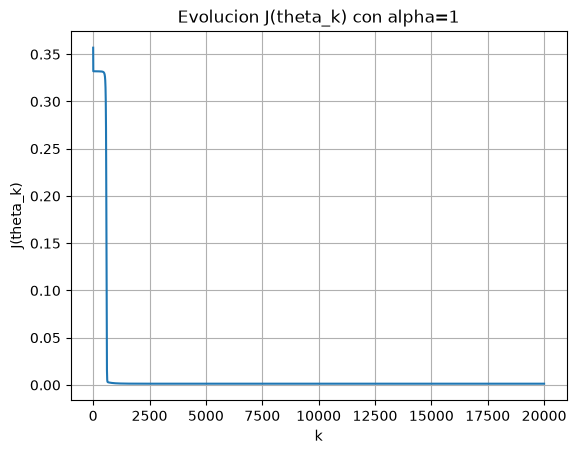

In [167]:
plt.figure()
plt.plot(hist_J)
plt.xlabel("k")
plt.ylabel("J(theta_k)")
plt.title("Evolucion J(theta_k) con alpha=1")
plt.grid(True)
plt.show()

Notamos una caída brusca del error antes de las primeras 2500 iteraciones, estas son las que más reducen el error. Luego, casi no cambia

## Inciso E
Obtenemos los 6 parámetros finales de la red, $\theta_{20.000}=(a_1,b_1,a_2,b_2,v,c)$ y el valor de la pérdida

In [168]:
a1, b1, a2, b2, v, c = theta # entrenado
print("a1 =", a1, ",b1 =", b1, "a2 =", a2, "b2 =",b2, "v =", v,"c =", c)
print("perdida =", J(theta))

a1 = -4.366758916139333 ,b1 = -0.7473648017493512 a2 = 3.5558165161029365 b2 = -1.62743181581607 v = 2.960878308189766 c = -0.43981266258598267
perdida = 0.001373561381572392


Notamos de los parametros que multiplican que $a_1<0$, $a_2>0$ y $v>0$, por regla de signos la salida de la red decrece

Calculamos la salida de la red en cada uno de los 100 valores de x que creamos entre [-1, 1], capa por capa

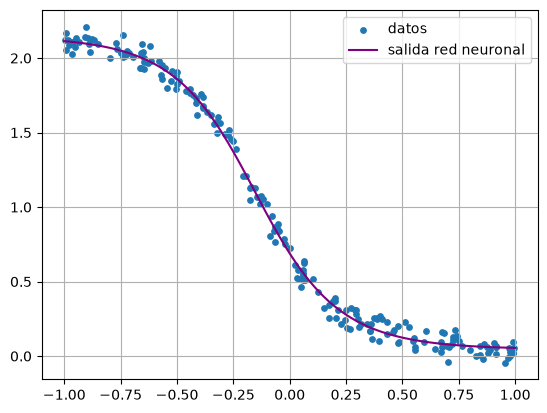

In [169]:
xcurva = np.linspace(-1, 1, 100)
z1 = a1*xcurva + b1 
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 
h2 = 1 / (1 + np.exp(-z2))
ycurva = c + v*h2 #salida

plt.figure()
plt.scatter(x, y, s=15, label="datos") # columnas csv
plt.plot(xcurva, ycurva, color="purple", label="salida red neuronal")
plt.legend()
plt.grid(True)
plt.show()

Notamos que la curva de la red sigue la forma y pasa entre los datos, por lo que la red logro ajustarse a ellos

## Inciso F
### Parte i.
Para comparar como baja el error con cada paso, mostramos la perdida y el error en las iteraciones 1, 500, 10000 y 20000

Nuevamente calculamos el descenso $\theta_{k+1}=\theta_k - \alpha \nabla J(\theta_k)$

In [ ]:
# inciso d
max_iter = 20000
theta = theta0.copy()
hist_J001 = np.zeros(max_iter)
for k in range(20000):
    g = grad_J(theta)
    theta = theta - 0.01 * g # alpha 0.01
    hist_J001[k] = J(theta)

print("1:", hist_J001[0]) # iteracion k
print("500:", hist_J001[499])
print("10000:", hist_J001[9999])
print("20000:", hist_J001[-1])

1: 0.596465422897854
500: 0.33200199905732114
10000: 0.33193505405534396
20000: 0.33188865121478256


In [171]:
theta = theta0.copy()
hist_J01 = np.zeros(max_iter)
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 0.1 * g # alpha 0.1
    hist_J01[k] = J(theta)

print("1:", hist_J01[0])
print("500:", hist_J01[499])
print("10000:", hist_J01[9999])
print("20000:", hist_J01[-1])

1: 0.5371563891740073
500: 0.33196255073548053
10000: 0.0017430827807612154
20000: 0.0013912641368709075


In [172]:
hist_J1 = np.zeros(max_iter)
theta = theta0.copy()
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 1 * g #alpha 1
    hist_J1[k] = J(theta)

print("1:", hist_J1[0])
print("500:", hist_J1[499])
print("10000:", hist_J1[9999])
print("20000:", hist_J1[-1])

1: 0.3569206523049593
500: 0.3294419314367054
10000: 0.0013747217008035235
20000: 0.001373561381572392


In [173]:
hist_J25 = np.zeros(max_iter)
theta = theta0.copy()
for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - 2.5 *g # alpha 2.5
    hist_J25[k] = J(theta)

print("1:", hist_J25[0])
print("500:", round(hist_J25[499]))
print("10000:", round(hist_J25[9999]))
print("20000:", round(hist_J25[-1]))

1: 1.69179105043178
500: 56097803145881029967872
10000: 56097803145881029967872
20000: 56097803145881029967872


- $\alpha=0.01$: el error parte mucho mas grande al inicio, disminuye y luego casi no cambia entre 10.000 y 20.000 el número es casi el mismo, entonces con un alfa muy pequeño no hay mucha variacion
- $\alpha=0.1$:el inicio es similar al anterior, pero luego el cambio es más significativo y se nota un descenso evidente del error
- $\alpha=1$: el error parte más bajo que en los anteriores y el resultado final es muy similar al de $\alpha=0.1$
- $\alpha=2.5$: las diferencias son mucho más significativas, pero no hay descenso, el error crece

En conclusión, con un alpha muy pequeño el error casi no baja y con un alpha muy grande el error aumenta en vez de disminuir. El mejor alpha es 1, ya que desde la primera iteración el error es más pequeño que con los otros alphas y luego decrece de forma notoria hasta llegar al menor error

### Parte ii.
10 $\theta_0$ distintos con elementos al azar en [-1,1] y otros 10 en [-5,5]

Sabiendo por enunciado que $h_2=\sigma(z_2)$ y que $\sigma'(t)=\sigma(t)\big(1-\sigma(t)\big)$, entonces $\sigma'(z_2)=\sigma(z_2)\big(1-\sigma(z_2)\big)=h_2(1-h_2)$ siendo t = z2 

In [174]:
np.random.seed(1)
J1 = np.zeros(10)
for i in range(10):
    theta = np.random.uniform(-1, 1, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2)))
    oz2 = h2 * (1 - h2)
    for k in range(20000):
        theta = theta - 1 * grad_J(theta) # alpha 1
    J1[i] = J(theta)
    t = a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2
    print("J:", J(theta), "t:", t, "o'(z2):", oz2)

J: 0.0013753007606708018 t: -1.0067002517394457 o'(z2): 0.19600237670478501
J: 0.0013752203865066716 t: -0.012266896056210036 o'(z2): 0.2499905954396838
J: 0.0013728430126302598 t: -0.3117552646163415 o'(z2): 0.24402260054539482
J: 0.0013751032935093892 t: 1.1569385801286722 o'(z2): 0.18199588099169337
J: 0.0013806764344295118 t: -1.4819679060491733 o'(z2): 0.15085711150671097
J: 0.0013739110030641256 t: 0.5025134962921745 o'(z2): 0.23485873931382648
J: 0.0013763149799730654 t: -0.13052574521427895 o'(z2): 0.2489382056079392
J: 0.001378932219305392 t: -0.6189175525438018 o'(z2): 0.22750830239809117
J: 0.0013742105600920865 t: 0.04013899112580677 o'(z2): 0.24989933087003838
J: 0.0013724668128327839 t: -0.6634499096658418 o'(z2): 0.22438881910847114


In [175]:
J5 = np.zeros(10)
for i in range(10):
    theta = np.random.uniform(-5, 5, 6)
    a1, b1, a2, b2, v, c = theta
    h2 = 1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2)))
    oz2 = h2 * (1 - h2)
    for k in range(20000):
        theta = theta - 1 * grad_J(theta) # alpha 1
    J5[i] = J(theta)
    t = a2 * (1 / (1 + np.exp(-(a1*x[0] + b1)))) + b2
    print("J:", J5[i], "t:", t, "o'(z2):", oz2)

J: 0.001396160133009028 t: -0.14608752691114402 o'(z2): 0.24867088225086129
J: 0.001405916229991759 t: 3.1114570822708263 o'(z2): 0.040819202976648664
J: 0.001402656806005092 t: -4.335219993233787 o'(z2): 0.012762451731096676
J: 0.331927389846129 t: 4.637846929346351 o'(z2): 0.009493851663160916
J: 0.33189428766799894 t: 3.940593746191302 o'(z2): 0.018702573790602202
J: 0.0013837496061716184 t: 0.2871199018035551 o'(z2): 0.24491760879495422
J: 0.0013629577983495869 t: -1.8297544332487545 o'(z2): 0.1191496199730467
J: 0.0014120280642523435 t: 1.8490601908348483 o'(z2): 0.11749182693020793
J: 0.0013995229160216902 t: -6.879114660348513 o'(z2): 0.001026940062439748
J: 0.0013903341928117915 t: 6.6359059939370315 o'(z2): 0.001308951228351146


In [176]:
print("promedio j1:", np.mean(J1), "promedio J5:", np.mean(J5))
print("j5 > J1:", np.mean(J5) > np.mean(J1))
print("j5/j1", np.mean(J5) / np.mean(J1))

print("mediana J1:", np.median(J1), "  mediana J5:", np.median(J5))
print("J5 > J1:", np.median(J5) > np.median(J1))
print("J5/j1", np.median(J5) / np.median(J1))

promedio j1: 0.001375497946301409 promedio J5: 0.06749750032607409
j5 > J1: True
j5/j1 49.071320322628495
mediana J1: 0.0013751618400080303   mediana J5: 0.0014010898610133911
J5 > J1: True
J5/j1 1.0188545233375654


- J final no siempre es el mismo, $J1$ y $J5$ son diferentes e incluso dentro de cada rango las inicializaciones no repiten. El promedio de $J5$ es 49 veces el de $J1$, aunque sus medianas son casi iguales
- Recordando por (a) que $\sigma'(t)$ alcanza su máximo cerca de $t=0$ y se hace cada vez más chico con $t$ lejos de 0. En los resultados con $\theta_0$ en $[-5,5]$ los valores de $t=z_2$ tienden a quedar más lejos de 0 que en $[-1,1]$, por lo que $\sigma'(z_2)$ es más pequeño. Como el gradiente se multiplica por $\sigma'$, también queda muy pequeño y los parámetros cambian muy poco en $\theta-\alpha \nabla J(\theta)$
- El descenso del gradiente disminuye el error, pero no asegura el mínimo global, ya que no se llega a un único valor, sino que los J finales varían en un rango muy pequeño, como si cerca del mínimo J fuera una llanura plana

## Inciso G
### parte i.

Cargamos los pares $x_i,\tilde y_i$ del segundo archivo

In [177]:
df = pd.read_csv("datos/datos_P2_g.csv") # inciso c
x_g = df["x"].to_numpy() 
y_g = df["y"].to_numpy()
x = x_g # por dedf de j y grad
y = y_g

In [178]:
alpha = 1.0 # inciso d
max_iter = 20000
theta_g = theta0.copy()
hist_Jg = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta_g)
    theta_g = theta_g - alpha * g
    hist_Jg[k] = J(theta_g)

print("J(theta0) =", J(theta0))
print("J(theta20000) =", hist_Jg[-1])

J(theta0) = 0.4681636039845724
J(theta20000) = 0.07929184106947007


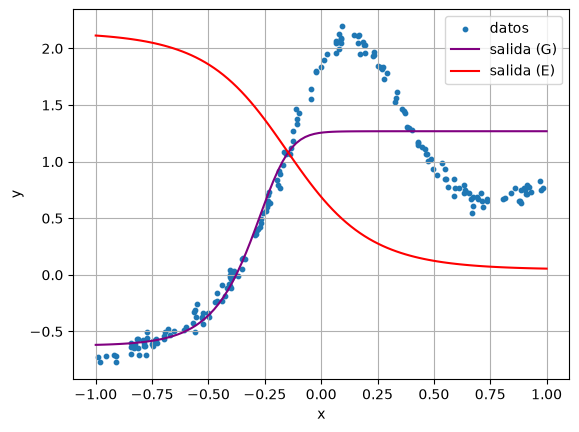

In [180]:
a1, b1, a2, b2, v, c = theta_g # entrenado
x_curvag = np.linspace(-1, 1, 100) # igual e
z1 = a1*x_curvag + b1 
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2
h2 = 1 / (1 + np.exp(-z2))
y_curvag = c + v*h2

plt.figure()
plt.scatter(x_g, y_g, s=10, label="datos")
plt.plot(x_curvag, y_curvag, color="purple", label="salida (G)")
plt.plot(xcurva, ycurva, color="red", label="salida (E)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Notamos que al inicio tanto los datos como la curva suben, luego la curva se aplana mientras los datos siguen subiendo y dejan de coincidir. Después se vuelven a cruzar en un solo punto, pero los datos bajan y la curva sigue plana. Por eso la red no logra ajustar estos datos, solo se ajusta a una parte. Comparando con E, la curva de G sube y la de E baja, como una solo sube y la otra solo baja, se cruzan en un solo punto

### Parte ii.

La salida de la red es $\hat y=c+v\,h_2=c+v\,\sigma\big(a_2\,\sigma(a_1x+b_1)+b_2\big)$. Veremos el signo de su derivada si cumple con siempre subir o siempre bajar, con 15 $\theta$ al azar en $[-1,1]$. Para cada uno elegimos 10 $x$ al azar en $[-1,1]$ y calculamos la derivada por diferencias centradas

In [195]:
np.random.seed(2)
h = 10**-5 # igual que en a
for i in range(15):
    a1, b1, a2, b2, v, c = np.random.uniform(-1, 1, 6)
    x = np.random.uniform(-1, 1, 10)
    y1 = c + v /(1 + np.exp(-(a2 / (1 + np.exp(-(a1*(x + h) + b1))) + b2)))
    y2 = c + v /(1 + np.exp(-(a2 / (1 + np.exp(-(a1*(x - h) + b1))) + b2)))
    dy = (y1 - y2) / (2*h)
    y_gorro = c + v / (1 + np.exp(-(a2 /(1 + np.exp(-(a1*x + b1))) + b2)))
    print("a1*a2*v:", a1*a2*v, "dy:", np.round(dy, 5)) # monotona
    print("c:", round(c, 3), "c+v:", round(c + v, 3), "y gorro:", np.round(y_gorro, 3)) # cota

a1*a2*v: 0.0020249842061467824 dy: [0.0001  0.0001  0.0001  0.0001  0.0001  0.0001  0.00011 0.0001  0.00011
 0.0001 ]
c: -0.339 c+v: -0.499 y gorro: [-0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415 -0.415]
a1*a2*v: 0.0051484794046368874 dy: [0.0003  0.00027 0.00028 0.0003  0.00029 0.00027 0.00029 0.0003  0.0003
 0.00028]
c: -0.869 c+v: -0.859 y gorro: [-0.865 -0.866 -0.866 -0.865 -0.866 -0.866 -0.866 -0.866 -0.865 -0.866]
a1*a2*v: 0.001727224153758903 dy: [0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011 0.00011
 0.00011]
c: 0.16 c+v: 0.747 y gorro: [0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421 0.421]
a1*a2*v: -0.0016830111360012772 dy: [-7.e-05 -8.e-05 -8.e-05 -8.e-05 -7.e-05 -7.e-05 -7.e-05 -7.e-05 -7.e-05
 -8.e-05]
c: 0.702 c+v: 0.434 y gorro: [0.617 0.617 0.617 0.617 0.617 0.617 0.617 0.617 0.617 0.617]
a1*a2*v: 0.11470233994831529 dy: [0.00549 0.00541 0.00537 0.00545 0.00547 0.0055  0.00544 0.00515 0.00548
 0.00538]
c: -0.117 c+v: 0.849 y gor

In [197]:
x_sort = np.sort(x)
y_sort = c + v * (1 / (1 + np.exp(-(a2 * (1 / (1 + np.exp(-(a1*x_sort + b1)))) + b2))))
print("x ordenados:", np.round(x_sort, 3))
print("y gorro:", np.round(y_sort, 3))

x ordenados: [-0.543 -0.339 -0.226 -0.171  0.253  0.285  0.426  0.54   0.71   0.874]
y gorro: [0.707 0.708 0.708 0.709 0.71  0.711 0.711 0.711 0.712 0.713]


In [ ]:
print("entre c y c+v:", (y_gorro - c) * (y_gorro - (c + v)) < 0)

entre c y c+v: [ True  True  True  True  True  True  True  True  True  True]


Notamos que en cada fila el signo de $a_1a_2v$ y el de todas las derivadas dy es el mismo, por lo que para cada $\theta$ la salida siempre crece o siempre decrece. Tambien verificamos que al ordenar los x, los y gorro van aumentando, siguiendo una única dirección, entonces es monótona

Para las cotas, notamos que todas y gorro está entre c y c+v, tambien al restarle cada una, una da positiva y la otra negativa, entonces su multiplicación es negativa, cumpliendo $c<\hat y<c+v$ o si v>0 $c+v<\hat y<c$ si $v<0$